# Lab 1.1 · Platform tour with DuckDB

Day 1 · Session 1 (The modern data platform) · 25 min. What you'll do:
- query every Qafila source **in place** (SQLite, JSON lines, CSV) with one engine, without loading anything first;
- profile the app database: volumes, keys, relationships, formats;
- start the **issue log**: the list of data problems the rest of the week fixes.

**Tasks**
- [ ] 1 · Query CSV, JSON lines and SQLite in place (5')
- [ ] 2 · SUMMARIZE the orders; daily volume chart (5')
- [ ] 3 · Check keys: duplicate customers, orphan orders (5')
- [ ] 4 · Inspect formats: mobiles, timestamps, prices (5')
- [ ] 5 · Write the issue log as a table (5')
- [ ] ✱ Stretch · Find the National Day spike and explain it

Please don't open `data/raw/DATA_ISSUES.txt` yet: finding the issues is the exercise.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "duckdb==1.5.6"], check=True)  # pin to uv.lock: newer DuckDB removed Relation.fetchone()
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # solutions/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import de_utils as U
U.ensure_data()
print("data:", U.RAW, "| quick mode:", U.QUICK)

data: /content/data-engineering/labs/data/raw | quick mode: False


In [2]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 80)
con = duckdb.connect()          # in-memory database: nothing is copied unless we ask
RAW = U.RAW.as_posix()          # DuckDB likes forward slashes, also on Windows

## 1 · Query CSV, JSON lines and SQLite in place (5')

Qafila's data lives in several places (see the table on the course slides). DuckDB reads each of them where it is:

| Source | Path | DuckDB reader |
|---|---|---|
| App database | `data/raw/qafila_oltp.sqlite` | `ATTACH ... (TYPE sqlite)` |
| Payments API dump | `data/raw/api/payments.jsonl` | `read_json_auto` |
| Delivery events | `data/raw/events/delivery_events.jsonl` | `read_json_auto` |
| Customer CDC | `data/raw/cdc/customers_changes.jsonl` | `read_json_auto` |
| Supplier prices | `data/raw/suppliers/prices_2026-W*.csv` | `read_csv` |
| Reviews | `data/raw/reviews.csv` | `read_csv` |

A raw file always deserves a look with your own eyes first:

In [3]:
U.peek(f"{RAW}/events/delivery_events.jsonl", 2)
print()
U.peek(f"{RAW}/reviews.csv", 3)

{"event_id": "ev-0001457", "order_id": 5040442, "store_id": "JED-01", "city": "Jeddah", "courier_id": "CR-JED-031", "event_type": "assigned", "event_time": "2026-09-24T05:14:52.016+03:00", "lat": 21.58424, "lon": 39.1723 …
{"event_id": "ev-0001458", "order_id": 5040442, "store_id": "JED-01", "city": "Jeddah", "courier_id": "CR-JED-031", "event_type": "picked_up", "event_time": "2026-09-24T05:24:21.703+03:00", "lat": 21.53236, "lon": 39.166 …

review_id,product_id,customer_id,rating,lang,review_text,created_at
700000,1022,102460,5,en,Best greek yogurt family size I have bought online,2026-09-06 06:09:14
700001,1163,104002,4,en,"Good quality, packaging could be better",2026-09-06 12:43:12


In [4]:
# CSV: the header and types are inferred (sniffed) from the file
con.sql(f"SELECT * FROM read_csv('{RAW}/reviews.csv') LIMIT 5").df()

,review_id,product_id,customer_id,rating,lang,review_text,created_at
0,700000,1022,102460,5,en,Best greek yogurt family size I have bought online,2026-09-06 06:09:14
1,700001,1163,104002,4,en,"Good quality, packaging could be better",2026-09-06 12:43:12
2,700002,1301,102999,1,ar,المنتج منتهي الصلاحية,2026-08-17 01:07:55
3,700003,1177,106704,5,ar,جودة ممتازة وسأطلب مرة أخرى,2026-09-18 20:39:03
4,700004,1317,103793,5,ar,جودة ممتازة وسأطلب مرة أخرى,2026-08-20 22:32:03


In [5]:
# The app database: attach it read-only and list its tables
con.sql(f"ATTACH '{RAW}/qafila_oltp.sqlite' AS app (TYPE sqlite, READ_ONLY)")
con.sql("SELECT table_name, estimated_size FROM duckdb_tables() WHERE database_name = 'app'").df()

,table_name,estimated_size
0,customers,7600
1,stores,11
2,products,355
3,orders,45765
4,order_items,172544


✏️ **Exercise** · Count the delivery events by `event_type`, straight from the JSON lines file, sorted by count.
Store the result as a pandas DataFrame in `events_by_type` (columns `event_type`, `n`).

In [6]:
events_by_type = con.sql(f"""
    SELECT event_type, count(*) AS n
    FROM read_json_auto('{RAW}/events/delivery_events.jsonl')
    GROUP BY event_type
    ORDER BY n DESC
""").df()
events_by_type

,event_type,n
0,assigned,5770
1,picked_up,5493
2,out_for_delivery,5490
3,delivered,5327
4,cancelled,278
5,failed,160


In [7]:
U.check(set(events_by_type.columns) == {"event_type", "n"}, "columns are event_type, n")
U.check(int(events_by_type.n.sum()) == 22518, f"{int(events_by_type.n.sum()):,} events in total")

✅ columns are event_type, n
✅ 22,518 events in total


🔍 **Look at** the counts: there are more `assigned` events than `delivered` + `cancelled` + `failed` together.
Some orders were cancelled before pickup, but keep this in mind for Task 3: are all of those events unique?

A join **across sources** works the same way. Revenue isn't stored anywhere: it is quantity × price − discount on
the order lines. Here is gross merchandise value (GMV) by city:

In [8]:
con.sql("""
    SELECT s.city,
           count(DISTINCT o.order_id)                                   AS orders,
           round(sum(i.quantity * i.unit_price - i.discount), 0)        AS gmv_sar
    FROM app.orders o
    JOIN app.stores s USING (store_id)
    JOIN app.order_items i USING (order_id)
    WHERE o.status = 'delivered'
    GROUP BY ALL
    ORDER BY gmv_sar DESC
""").df()

,city,orders,gmv_sar
0,Riyadh,20647,3324640.0
1,Jeddah,12730,2032240.0
2,Dammam,7042,1137804.0


## 2 · SUMMARIZE the orders; daily volume chart (5')

`SUMMARIZE` profiles every column at once: type, min, max, approximate distinct count, null percentage.

In [9]:
con.sql("SUMMARIZE app.orders").df()[["column_name", "column_type", "min", "max", "approx_unique", "null_percentage"]]

,column_name,column_type,min,max,approx_unique,null_percentage
0,order_id,BIGINT,5000001,5045766,52877,0.00
1,customer_id,BIGINT,100000,107586,8101,0.00
2,store_id,VARCHAR,DMM-01,RUH-06,12,0.00
3,status,VARCHAR,cancelled,refunded,4,0.00
4,payment_method,VARCHAR,apple_pay,wallet,4,0.00
5,promo_code,VARCHAR,FREEDEL,WELCOME10,4,86.46
6,delivery_fee,DOUBLE,0.0,9.0,2,0.00
7,created_at,VARCHAR,2026-08-01 02:57:13,2026-09-30 20:57:37,54998,0.00
8,updated_at,VARCHAR,2026-08-01 03:54:44,2026-09-30 23:59:59,41042,0.00


Notice `created_at` is a **string** (`VARCHAR`): SQLite has no real timestamp type. The app stores UTC as text.
The business, however, counts days in Riyadh time (UTC+3): an order at 22:30 UTC on 22 September is a 23 September order.

✏️ **Exercise** · Build `daily`: one row per **Riyadh** calendar day with the number of orders, columns `day` and `orders`,
ordered by day. Hint: `created_at::TIMESTAMP + INTERVAL 3 HOUR` then `::DATE`.

✅ 61 days (Aug + Sep 2026)


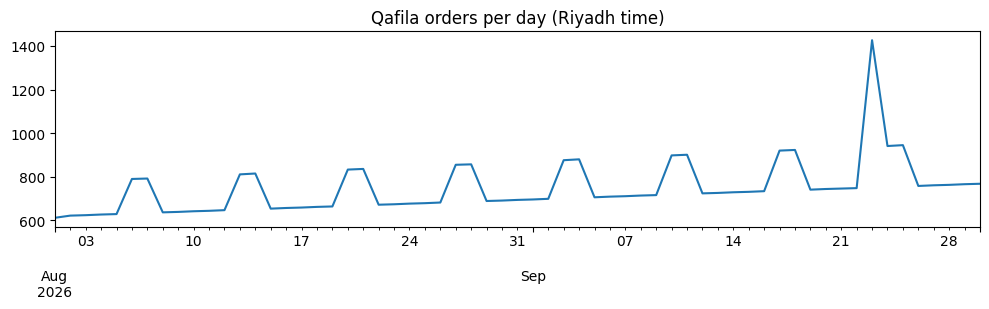

In [10]:
daily = con.sql("""
    SELECT (created_at::TIMESTAMP + INTERVAL 3 HOUR)::DATE AS day, count(*) AS orders
    FROM app.orders
    GROUP BY day
    ORDER BY day
""").df()
U.check(len(daily) == 61, f"{len(daily)} days (Aug + Sep 2026)")
ax = daily.plot(x="day", y="orders", figsize=(10, 3.2), legend=False, title="Qafila orders per day (Riyadh time)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

🔍 **Look at** the weekly rhythm (Thursday and Friday peaks), the slow growth, and one day that stands out (the ✱ Stretch).

## 3 · Check keys: duplicate customers, orphan orders (5')

A primary key in the source database only guarantees the **ID** is unique, not that each **person** appears once.

✏️ **Exercise** · Compute three numbers:
- `dup_people`: how many `national_id` values appear on more than one customer row;
- `orphan_orders`: orders whose `customer_id` has no row in `app.customers`;
- `negative_lines`: order lines with `quantity < 0`.

In [11]:
dup_people = con.sql("""
    SELECT count(*) FROM (
        SELECT national_id FROM app.customers GROUP BY national_id HAVING count(*) > 1
    )""").fetchone()[0]
orphan_orders = con.sql("""
    SELECT count(*) FROM app.orders o
    LEFT JOIN app.customers c USING (customer_id)
    WHERE c.customer_id IS NULL""").fetchone()[0]
negative_lines = con.sql("SELECT count(*) FROM app.order_items WHERE quantity < 0").fetchone()[0]
print(f"duplicate people: {dup_people} | orphan orders: {orphan_orders} | negative lines: {negative_lines}")
U.check(dup_people > 40, "some people have several customer accounts")
U.check(orphan_orders > 0, "some orders point to customers that no longer exist")

duplicate people: 58 | orphan orders: 1040 | negative lines: 142
✅ some people have several customer accounts
✅ some orders point to customers that no longer exist


Look at one duplicated person: what differs between the two rows?

In [12]:
con.sql("""
    SELECT customer_id, full_name, email, mobile, national_id, created_at
    FROM app.customers
    WHERE national_id = (SELECT national_id FROM app.customers GROUP BY 1 HAVING count(*) > 1 ORDER BY 1 LIMIT 1)
""").df()

,customer_id,full_name,email,mobile,national_id,created_at
0,100162,بندر الجهني,bandar.148@icloud.com,0596390578,1118790243,2025-05-30 19:15:39
1,106058,بندر الجهني,BANDAR.148@ICLOUD.COM,+966 50 525 5034,1118790243,2025-11-27 19:15:39


🔍 Same person, same national ID, but the email is upper-cased and the mobile number is written differently. A
`DISTINCT` on email or mobile would not catch this. And the orphan orders? Those customers were **hard-deleted**
(an erasure request under the PDPL, as we'll see in Lab 1.4). Their orders remain, so every report that inner-joins
orders to customers silently loses revenue.

## 4 · Inspect formats: mobiles, timestamps, prices (5')

Formats are where integrations break. Classify the shapes of a column with regular expressions.

In [13]:
con.sql(r"""
    SELECT CASE
             WHEN regexp_full_match(mobile, '\+9665\d{8}')          THEN '+9665XXXXXXXX'
             WHEN regexp_full_match(mobile, '05\d{8}')              THEN '05XXXXXXXX'
             WHEN regexp_full_match(mobile, '9665\d{8}')            THEN '9665XXXXXXXX'
             WHEN regexp_full_match(mobile, '\+966 5\d \d{3} \d{4}') THEN '+966 5X XXX XXXX'
             ELSE 'other' END AS mobile_format,
           count(*) AS n
    FROM app.customers GROUP BY ALL ORDER BY n DESC
""").df()

,mobile_format,n
0,+9665XXXXXXXX,3350
1,05XXXXXXXX,2251
2,+966 5X XXX XXXX,1072
3,9665XXXXXXXX,766
4,other,3


✏️ **Exercise** · Do the same for `event_time` in the delivery events. Build `time_formats` with columns `format`, `n`,
distinguishing: ISO with `+03:00` offset, ISO with `Z` (UTC), and epoch milliseconds (digits only).

In [14]:
time_formats = con.sql(rf"""
    SELECT CASE
             WHEN event_time LIKE '%+03:00'                 THEN 'ISO +03:00'
             WHEN event_time LIKE '%Z'                      THEN 'ISO Z (UTC)'
             WHEN regexp_full_match(event_time, '\d{{13}}') THEN 'epoch ms'
             ELSE 'other' END AS format,
           count(*) AS n
    FROM read_json_auto('{RAW}/events/delivery_events.jsonl')
    GROUP BY ALL ORDER BY n DESC
""").df()
time_formats

,format,n
0,ISO +03:00,18031
1,ISO Z (UTC),3372
2,epoch ms,1115


In [15]:
U.check(len(time_formats) == 3 and "other" not in set(time_formats.format), "three timestamp formats, nothing else")

✅ three timestamp formats, nothing else


And the supplier price files: compare the inferred schema of two weeks.

In [16]:
for week in ["W37", "W38", "W39"]:
    cols = con.sql(f"DESCRIBE SELECT * FROM read_csv('{RAW}/suppliers/prices_2026-{week}.csv')").df()
    print(week, dict(zip(cols.column_name, cols.column_type)))

W37 {'supplier_id': 'VARCHAR', 'sku': 'VARCHAR', 'product_name_ar': 'VARCHAR', 'unit_cost': 'DOUBLE', 'valid_from': 'DATE', 'min_order_qty': 'BIGINT'}
W38 {'supplier_id': 'VARCHAR', 'sku': 'VARCHAR', 'product_name_ar': 'VARCHAR', 'unit_cost': 'VARCHAR', 'valid_from': 'DATE', 'min_order_qty': 'BIGINT'}
W39 {'supplier_id': 'VARCHAR', 'sku': 'VARCHAR', 'product_name_ar': 'VARCHAR', 'valid_from': 'DATE', 'min_order_qty': 'BIGINT', 'cost_sar': 'DOUBLE', 'currency': 'VARCHAR'}


In [17]:
con.sql(f"SELECT sku, unit_cost FROM read_csv('{RAW}/suppliers/prices_2026-W38.csv') WHERE unit_cost NOT LIKE '%,%' LIMIT 3").df()

,sku,unit_cost
0,QF-BEV-1171,٨٫٦٥
1,QF-DAT-1221,٥٣٫٧١
2,QF-FRU-1096,٢٫٦٦


🔍 Week 37: `unit_cost` is a `DOUBLE`. Week 38: the same column is `VARCHAR` because the supplier's Excel export used
decimal commas (`9,49`) and some Arabic-Indic digits (`٩٫٤٩`). Week 39: `unit_cost` is gone, `cost_sar` and `currency`
appeared. Nobody told us. This is **schema drift**.

## 5 · Write the issue log as a table (5')

An issue log is the cheapest documentation a data team has. Every row becomes a test (Day 2) or a contract clause (Day 4).

✏️ **Exercise** · Add the issues you found as rows of `issues` (at least 6). Keep the columns:
`source`, `issue`, `evidence` (a number or example), `severity` (`high`/`medium`/`low`), `fix_in` (where it gets fixed).
Two rows are given.

In [18]:
issues = [
    {"source": "app.orders", "issue": "orders of erased customers (orphan customer_id)", "evidence": orphan_orders,
     "severity": "high", "fix_in": "Day 2 model: left join + 'unknown customer' member"},
    {"source": "suppliers", "issue": "W38 decimal commas and Arabic-Indic digits", "evidence": "9,49 / ٩٫٤٩",
     "severity": "medium", "fix_in": "Day 2 Pandera validation + parsing"},
]
issues += [
    {"source": "app.customers", "issue": "duplicate accounts for the same national_id", "evidence": dup_people,
     "severity": "high", "fix_in": "Day 2 staging: dedupe on national_id"},
    {"source": "app.customers", "issue": "mobile numbers in 4 formats", "evidence": "+9665…, 05…, 9665…, +966 5…",
     "severity": "medium", "fix_in": "Day 2 staging: normalize to E.164"},
    {"source": "app.order_items", "issue": "negative quantities", "evidence": negative_lines,
     "severity": "medium", "fix_in": "Day 2 tests + quarantine"},
    {"source": "app.orders", "issue": "timestamps are UTC text; business days are Riyadh time", "evidence": "VARCHAR created_at",
     "severity": "medium", "fix_in": "Day 2 staging: cast + convert time zone"},
    {"source": "delivery_events", "issue": "three timestamp formats", "evidence": len(time_formats),
     "severity": "high", "fix_in": "Day 2 staging / Day 3 streaming parser"},
    {"source": "suppliers", "issue": "W39 renamed unit_cost -> cost_sar, added currency", "evidence": "schema drift",
     "severity": "high", "fix_in": "Day 4 data contract"},
]
issue_log = pd.DataFrame(issues)
U.check(len(issue_log) >= 8, f"{len(issue_log)} issues logged")
U.check(set(issue_log.severity) <= {"high", "medium", "low"}, "severity uses the agreed levels")
issue_log

✅ 8 issues logged
✅ severity uses the agreed levels


,source,issue,evidence,severity,fix_in
0,app.orders,orders of erased customers (orphan customer_id),1040,high,Day 2 model: left join + 'unknown customer' member
1,suppliers,W38 decimal commas and Arabic-Indic digits,"9,49 / ٩٫٤٩",medium,Day 2 Pandera validation + parsing
2,app.customers,duplicate accounts for the same national_id,58,high,Day 2 staging: dedupe on national_id
3,app.customers,mobile numbers in 4 formats,"+9665…, 05…, 9665…, +966 5…",medium,Day 2 staging: normalize to E.164
4,app.order_items,negative quantities,142,medium,Day 2 tests + quarantine
5,app.orders,timestamps are UTC text; business days are Riyadh time,VARCHAR created_at,medium,Day 2 staging: cast + convert time zone
6,delivery_events,three timestamp formats,3,high,Day 2 staging / Day 3 streaming parser
7,suppliers,"W39 renamed unit_cost -> cost_sar, added currency",schema drift,high,Day 4 data contract


Save it: issue logs belong in the repository next to the code, not in someone's head.

In [19]:
out = U.lab_dir("D1_1") / "issue_log.csv"
issue_log.to_csv(out, index=False)
print("saved", out)

saved /content/data-engineering/labs/artifacts/D1_1/issue_log.csv


Now compare your log with `data/raw/DATA_ISSUES.txt`. Which problems did you miss? Two hints: look for duplicate
`event_id`s in the delivery events, and for SKUs with trailing spaces in `app.products`.

In [20]:
print(open(U.RAW / "DATA_ISSUES.txt", encoding="utf-8").read())
con.sql(f"""
    SELECT count(*) - count(DISTINCT event_id) AS duplicate_events
    FROM read_json_auto('{RAW}/events/delivery_events.jsonl')
""").df()

customers   duplicate accounts (same national_id, different email casing); mixed mobile formats;
            ~5% missing email; Arabic names with tatweel/diacritics; soft deletes (is_deleted)
orders      orders of customers erased under PDPL (customer row hard-deleted -> orphan FK)
order_items a handful of negative quantities
products    two SKUs with trailing spaces
payments    failed attempts before a capture; a few amounts that do not match the order;
            'wallet_provider' field appears from 2026-09-15 (schema evolution); API rate limits
cdc         redelivered (duplicate) events; events arrive out of order (sort by lsn)
deliveries  duplicate events; late events (courier offline); three timestamp formats
suppliers   W38 uses decimal commas and Arabic-Indic digits; W39 renames unit_cost -> cost_sar,
            adds currency, and has zero/negative costs and unknown SKUs



,duplicate_events
0,312


## ✱ Stretch · Find the National Day spike and explain it

One day in `daily` has almost twice the usual orders. Which day is it, and what does the `promo_code` column say about it?
Saudi National Day is 23 September.

In [21]:
peak = daily.loc[daily.orders.idxmax()]
print("peak day:", peak.day.date(), "| orders:", peak.orders)
con.sql("""
    SELECT coalesce(promo_code, '(none)') AS promo, count(*) AS orders
    FROM app.orders
    WHERE (created_at::TIMESTAMP + INTERVAL 3 HOUR)::DATE = DATE '2026-09-23'
    GROUP BY ALL ORDER BY orders DESC
""").df()

peak day: 2026-09-23 | orders: 1426


,promo,orders
0,WATANI26,839
1,(none),526
2,WELCOME10,25
3,FREEDEL,20
4,WEEKEND15,16


## Checkpoint

1. Why did we never copy the SQLite tables into DuckDB in this lab? When would you copy them?
2. Orders are stored with UTC timestamps. Which reports change if you count days in UTC instead of Riyadh time?
3. Two customer rows share a national ID. Should the source system or the data platform fix that? Who do you tell?
4. Pick the one issue from your log that would hurt a revenue dashboard most. Why that one?